# 06 — Treinamento com fine-tuning em duas etapas

**TCC UNIP 2026** · Etapa 6 de 9 do pipeline · Seção 4.5.6 do trabalho escrito.

**Objetivo:** executar as ablações (DullRazor, cor, Focal Loss e escalonador), aplicar a regra de seleção da configuração final e treinar a ResNet50 e a EfficientNet-B0 com ajuste fino em duas etapas.

**Entradas:**
- CSVs das partições e imagens processadas (notebook 03)

**Saídas:**
- `experimentos/` (resultados das ablações e `config_final.json`)
- `modelo_resnet50.pt`, `modelo_efficientnet_b0.pt`, `curvas_treinamento/`, `resultados_comparacao.json`

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


## Funções do pipeline de dados (reutilizadas do notebook 04)

In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
import pandas as pd
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
SAIDA_BASE = "/content/data/processed"
MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
BATCH_SIZE = 32
NUM_WORKERS = 2   # o Colab tem 2 CPUs; mais workers que isso só atrapalha (ver aviso do DataLoader)

# Modo de teste rápido (opcional): use p.ex. 0.05 para treinar/avaliar com ~5% das imagens
# e conferir se o notebook inteiro roda, antes de gastar horas de GPU. None = usa tudo.
FRACAO_DADOS_DEBUG = None

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# TRANSFORMS
# ============================================================
# ATENÇÃO (teste de cor): o ColorJitter do Albumentations, quando 'hue' não é informado, aplica
# uma rotação de MATIZ por padrão (nas versões 2.x: até ±0.5 do círculo cromático, i.e. qualquer cor).
# Isso muda a cor da lesão — um sinal clínico central (critério "C" do ABCDE) — em metade das imagens.
# Esta é a configuração da versão anterior e é mantida como variante "original" para comparação.
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# Val/teste: SEM augmentation aleatório — só normalização, para avaliação justa e reprodutível
eval_transform = A.Compose([
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# ------------------------------------------------------------
# Variantes de augmentation de COR (usadas no "Teste de alterações de cor")
#   "original"         -> a configuração acima (brilho, contraste, saturação E matiz padrão do Albumentations)
#   "brilho_contraste" -> só brilho e contraste (±20%); saturação e matiz FIXOS (cor da lesão preservada)
#   "sem_cor"          -> nenhuma alteração de cor (só flips/rotações/escala)
# ------------------------------------------------------------
def construir_train_transform(variante_cor="original"):
    if variante_cor == "original":
        return train_transform
    if variante_cor == "brilho_contraste":
        cor = [A.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                             saturation=(1.0, 1.0), hue=(0.0, 0.0), p=0.5)]
    elif variante_cor == "sem_cor":
        cor = []
    else:
        raise ValueError(f"Variante de cor desconhecida: {variante_cor}")
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        *cor,
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
        A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
        ToTensorV2(),
    ])

TRAIN_TRANSFORMS = {v: construir_train_transform(v)
                    for v in ["original", "brilho_contraste", "sem_cor"]}

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# DATASET
# ============================================================
from PIL import Image, ImageEnhance

def aplicar_perturbacao_cor(img_rgb, brilho=0.0, contraste=0.0, saturacao=0.0, matiz=0.0):
    """Perturbação DETERMINÍSTICA de cor (usada só na avaliação de robustez, nunca no treino).
    brilho/contraste/saturacao: variação relativa (0.2 = +20%, -0.2 = -20%).
    matiz: fração do círculo cromático (0.1 = 36 graus)."""
    pil = Image.fromarray(img_rgb)
    if brilho:
        pil = ImageEnhance.Brightness(pil).enhance(1.0 + brilho)
    if contraste:
        pil = ImageEnhance.Contrast(pil).enhance(1.0 + contraste)
    if saturacao:
        pil = ImageEnhance.Color(pil).enhance(1.0 + saturacao)
    if matiz:
        h, s, v = pil.convert("HSV").split()
        deslocamento = int(round(matiz * 255))
        h = h.point(lambda x: (x + deslocamento) % 256)
        pil = Image.merge("HSV", (h, s, v)).convert("RGB")
    return np.array(pil)


class DermatoDataset(Dataset):
    def __init__(self, dataframe, mapa_classes, transform=None, perturbacao=None):
        self.df = dataframe.reset_index(drop=True)
        self.mapa_classes = mapa_classes
        self.transform = transform
        self.perturbacao = perturbacao   # dict p/ aplicar_perturbacao_cor (None = sem perturbação)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        linha = self.df.iloc[idx]
        img = cv2.imread(linha["caminho_processado"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.perturbacao:
            img = aplicar_perturbacao_cor(img, **self.perturbacao)

        if self.transform:
            img = self.transform(image=img)["image"]

        rotulo = self.mapa_classes[linha["classe"]]
        return img, rotulo

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# CRIAÇÃO DOS DATALOADERS
# ============================================================
# Qual versão das imagens é usada por padrão: "com_dullrazor" (train.csv...) ou "sem_dullrazor".
# A célula de seleção da configuração final (mais adiante) atualiza este valor.
DADOS_ATIVOS = "com_dullrazor"

def caminho_csv_split(split, dados):
    sufixo = "" if dados == "com_dullrazor" else f"_{dados}"
    return f"{SAIDA_BASE}/{split}{sufixo}.csv"

def _ler_split(split, dados):
    df = pd.read_csv(caminho_csv_split(split, dados), low_memory=False)
    if FRACAO_DADOS_DEBUG:
        df = (df.groupby("classe", group_keys=False)
                .apply(lambda g: g.sample(n=max(2, int(len(g) * FRACAO_DADOS_DEBUG)),
                                          random_state=SEED)
                       if len(g) > 2 else g))
    return df

def criar_dataloaders(batch_size=BATCH_SIZE, dados=None, variante_cor="original"):
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    df_val = _ler_split("val", dados)
    df_teste = _ler_split("test", dados)

    classes_ordenadas = sorted(df_treino["classe"].unique())
    mapa_classes = {nome: idx for idx, nome in enumerate(classes_ordenadas)}
    print("Mapa de classes:", mapa_classes)
    print(f"Dados: {dados} | augmentation de cor: {variante_cor}")

    ds_treino = DermatoDataset(df_treino, mapa_classes, transform=TRAIN_TRANSFORMS[variante_cor])
    ds_val = DermatoDataset(df_val, mapa_classes, transform=eval_transform)
    ds_teste = DermatoDataset(df_teste, mapa_classes, transform=eval_transform)

    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=pin,
                               persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(ds_teste, batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin)

    return train_loader, val_loader, test_loader, mapa_classes


def criar_loader_teste(dados=None, perturbacao=None, batch_size=BATCH_SIZE):
    """DataLoader de TESTE (sem augmentation), opcionalmente com perturbação determinística
    de cor — usado na avaliação de robustez a brilho/contraste."""
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    mapa_classes = {n: i for i, n in enumerate(sorted(df_treino["classe"].unique()))}
    ds = DermatoDataset(_ler_split("test", dados), mapa_classes,
                        transform=eval_transform, perturbacao=perturbacao)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
    return loader, mapa_classes

### TREINAMENTO COMPLETO

TREINAMENTO COMPLETO — Fine-tuning em duas etapas, comparando ResNet50 e
EfficientNet-B0 (item 3.5 do TCC).

Etapa 1 (por arquitetura): treina só a cabeça de classificação, com as
  camadas convolucionais congeladas (features do ImageNet mantidas).
Etapa 2: descongela toda a rede e faz fine-tuning com taxa de aprendizado
  bem menor, ajustando as representações para o domínio das lesões de pele.

Usa early stopping baseado no F1-macro de validação, class_weights (ou Focal Loss) para lidar
com o desbalanceamento das classes, e salva o melhor checkpoint de cada
arquitetura para comparação final.

O Dataset PyTorch e os DataLoaders são definidos nas células anteriores deste notebook; não é necessário um arquivo externo `dataset_pytorch.py`.

MELHORIAS DESTA VERSÃO (sobre o treinamento anterior):
  - Escalonador de taxa de aprendizado (cosseno com warmup) e LR da etapa 2 de 1e-5 -> 1e-4
    (antes a loss ainda caía na época 20: o modelo estava subtreinado);
  - Focal Loss opcional (CFG['perda'] = 'focal');
  - Precisão mista (AMP) e pesos de classe calculados sem percorrer o DataLoader (mais rápido);
  - Melhor checkpoint escolhido por F1-macro de validação, não pela loss;
  - Sementes fixas para comparações justas entre experimentos.


In [ ]:
import os
import copy
import time
import json
import math
import random
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import LambdaLR, ReduceLROnPlateau
from torchvision import models
import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, f1_score, balanced_accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

#from dataset_pytorch import criar_dataloaders


def coletar_metadados_ambiente():
    """Metadados reais da execução Colab para documentar reprodutibilidade."""
    import platform
    import sys
    dados = {
        "python": sys.version.split()[0], "plataforma": platform.platform(),
        "pytorch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "cuda_disponivel": bool(torch.cuda.is_available()), "cuda_versao_pytorch": torch.version.cuda,
        "dispositivo": str(DEVICE), "semente": int(SEED),
        "batch_size": int(BATCH_SIZE), "num_workers": int(NUM_WORKERS),
    }
    if torch.cuda.is_available():
        dados["gpu"] = torch.cuda.get_device_name(0)
        dados["memoria_gpu_total_gb"] = round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2)
    else:
        dados["gpu"] = None
    return dados


In [ ]:
# ============================================================
# CONFIGURAÇÃO GERAL
# ============================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
USAR_AMP = DEVICE.type == "cuda"   # precisão mista (fp16): ~2x mais rápido na T4, sem perda de qualidade

# Etapa 1 (cabeça congelada): converge rápido, não precisa de muitas épocas
EPOCAS_ETAPA1 = 6
LR_ETAPA1 = 1e-3

# Etapa 2 (fine-tuning completo)
# LR_ETAPA2 era 1e-5 e constante: com 20 épocas a loss ainda estava caindo (subajuste).
# Agora o pico é 1e-4, com aquecimento (warmup) e decaimento cosseno (escalonador).
EPOCAS_ETAPA2 = 24
LR_ETAPA2 = 1e-4
FATOR_LR_CABECA = 10.0   # a cabeça (camada nova) aprende 10x mais rápido que o corpo pré-treinado

PACIENCIA_EARLY_STOPPING = 7  # nº de épocas sem melhora antes de parar
MONITOR_METRICA = "f1_macro"  # critério de early stopping/melhor checkpoint: "f1_macro" (recomendado
                              # com classes desbalanceadas) ou "loss" (comportamento anterior)

# Configuração padrão do treinamento (cada chave pode ser sobrescrita nos experimentos)
CFG_PADRAO = {
    "dados": "com_dullrazor",        # "com_dullrazor" | "sem_dullrazor"
    "cor": "brilho_contraste",       # "original" | "brilho_contraste" | "sem_cor"
    "perda": "ce",                   # "ce" (CrossEntropy ponderada) | "focal"
    "focal_gamma": 2.0,
    "focal_alpha": "raiz",           # peso por classe na focal: "pesos" | "raiz" (√pesos) | "nenhum"
    "scheduler": "cosine",           # "cosine" | "plateau" | "nenhum"
    "epocas_e1": EPOCAS_ETAPA1,
    "epocas_e2": EPOCAS_ETAPA2,
    "lr_e1": LR_ETAPA1,
    "lr_e2": LR_ETAPA2,
    "fator_lr_cabeca": FATOR_LR_CABECA,
    "seed": 42,
}
CFG_FINAL = dict(CFG_PADRAO)   # atualizada pela célula de seleção (após os experimentos)

In [ ]:
# ============================================================
# UTILITÁRIOS DE TREINO MELHORADO: semente, Focal Loss, escalonador e validação completa
# ============================================================
def fixar_semente(seed=42):
    """Reprodutibilidade: comparações entre experimentos só fazem sentido com a mesma semente."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class FocalLoss(nn.Module):
    """
    Focal Loss multiclasse (Lin et al., 2017):  FL = -alpha_t * (1 - p_t)^gamma * log(p_t)
    O fator (1 - p_t)^gamma reduz a contribuição dos exemplos FÁCEIS (ex.: nevos já bem
    classificados) e concentra o gradiente nos exemplos DIFÍCEIS e nas classes raras.
      gamma = 0  -> equivale à Cross-Entropy (ponderada, se houver alpha)
      alpha      -> vetor de pesos por classe (opcional)
    """
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("alpha", alpha if alpha is not None else None)

    def forward(self, logits, alvo):
        logp = F.log_softmax(logits.float(), dim=1)             # sempre em fp32 (estável sob AMP)
        logp_t = logp.gather(1, alvo.unsqueeze(1)).squeeze(1)
        p_t = logp_t.exp()
        perda = -((1.0 - p_t) ** self.gamma) * logp_t
        if self.alpha is not None:
            perda = perda * self.alpha[alvo]
        return perda.mean()


def criar_criterio(cfg, pesos_classe):
    if cfg["perda"] == "focal":
        alpha = {"pesos": pesos_classe,
                 "raiz": pesos_classe.sqrt(),
                 "nenhum": None}[cfg["focal_alpha"]]
        return FocalLoss(gamma=cfg["focal_gamma"], alpha=alpha)
    return nn.CrossEntropyLoss(weight=pesos_classe)


def criar_scheduler(otimizador, tipo, num_epocas, passos_por_epoca,
                    epocas_warmup=1, lr_min_fator=0.01):
    """
    Retorna (scheduler, modo). modo diz quando chamar scheduler.step():
      "batch"      -> a cada batch (cosseno com warmup linear)
      "epoca_val"  -> uma vez por época, passando o F1-macro de validação (ReduceLROnPlateau)
      None         -> sem escalonador (taxa de aprendizado constante)
    """
    if tipo in (None, "nenhum"):
        return None, None

    if tipo == "cosine":
        total = max(1, num_epocas * passos_por_epoca)
        warm = max(1, min(epocas_warmup * passos_por_epoca, total // 2))

        def fator(passo):
            if passo < warm:
                return (passo + 1) / warm
            progresso = min(1.0, (passo - warm) / max(1, total - warm))
            return lr_min_fator + (1 - lr_min_fator) * 0.5 * (1 + math.cos(math.pi * progresso))

        return LambdaLR(otimizador, lr_lambda=fator), "batch"

    if tipo == "plateau":
        return ReduceLROnPlateau(otimizador, mode="max", factor=0.5, patience=2), "epoca_val"

    raise ValueError(f"Escalonador desconhecido: {tipo}")


def validar_epoca_completa(modelo, loader, criterio):
    """Como validar_epoca, mas devolve também F1-macro e sensibilidade de melanoma
    (as métricas que importam com classes desbalanceadas)."""
    modelo.eval()
    perda_total, total = 0.0, 0
    todos_rotulos, todas_preds = [], []

    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens)
                perda = criterio(saidas, rotulos)
            perda_total += perda.item() * imagens.size(0)
            total += imagens.size(0)
            todas_preds.append(saidas.argmax(dim=1).cpu())
            todos_rotulos.append(rotulos.cpu())

    rotulos_np = torch.cat(todos_rotulos).numpy()
    preds_np = torch.cat(todas_preds).numpy()
    mapa = loader.dataset.mapa_classes
    f1_macro = f1_score(rotulos_np, preds_np, labels=list(range(len(mapa))),
                        average="macro", zero_division=0)
    idx_mel = mapa.get("melanoma")
    if idx_mel is not None and (rotulos_np == idx_mel).any():
        sens_mel = float(((preds_np == idx_mel) & (rotulos_np == idx_mel)).sum() / (rotulos_np == idx_mel).sum())
    else:
        sens_mel = float("nan")

    return {"loss": perda_total / total, "acc": float((rotulos_np == preds_np).mean()),
            "f1_macro": float(f1_macro), "sens_melanoma": sens_mel}

In [ ]:
# ============================================================
# CONSTRUÇÃO DOS MODELOS
# ============================================================
def construir_modelo(arquitetura: str, num_classes: int):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
        camada_classificadora = modelo.fc
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
        camada_classificadora = modelo.classifier[1]
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    return modelo.to(DEVICE), camada_classificadora


In [ ]:
def congelar_camadas_base(modelo, camada_classificadora):
    for param in modelo.parameters():
        param.requires_grad = False
    for param in camada_classificadora.parameters():
        param.requires_grad = True
    return modelo

In [ ]:
def descongelar_tudo(modelo):
    for param in modelo.parameters():
        param.requires_grad = True
    return modelo

In [ ]:
# ============================================================
# CLASS WEIGHTS
# ============================================================
def calcular_pesos_classe(train_loader, mapa_classes):
    # Lê os rótulos direto do DataFrame do dataset: é o mesmo resultado de percorrer o loader,
    # mas sem decodificar e aumentar ~15 mil imagens só para contar classes (economiza ~1 min).
    todos_rotulos = train_loader.dataset.df["classe"].map(mapa_classes).tolist()

    classes_presentes = sorted(set(todos_rotulos))
    pesos = compute_class_weight(
        class_weight="balanced",
        classes=np.array(classes_presentes),
        y=np.array(todos_rotulos),
    )
    vetor_pesos = np.ones(len(mapa_classes))
    for classe_idx, peso in zip(classes_presentes, pesos):
        vetor_pesos[classe_idx] = peso

    return torch.tensor(vetor_pesos, dtype=torch.float32).to(DEVICE)

In [ ]:
# ============================================================
# LOOPS DE TREINO / VALIDAÇÃO
# ============================================================
def treinar_epoca(modelo, loader, criterio, otimizador, scaler=None, scheduler=None):
    """scheduler: se informado, é chamado a cada batch (modo "batch" do criar_scheduler)."""
    modelo.train()
    perda_total, acertos, total = 0.0, 0, 0

    for imagens, rotulos in loader:
        imagens, rotulos = imagens.to(DEVICE, non_blocking=True), rotulos.to(DEVICE, non_blocking=True)

        otimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)

        if scaler is not None and scaler.is_enabled():
            scaler.scale(perda).backward()
            scaler.step(otimizador)
            scaler.update()
        else:
            perda.backward()
            otimizador.step()

        if scheduler is not None:
            scheduler.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
def validar_epoca(modelo, loader, criterio):
    modelo.eval()
    perda_total, acertos, total = 0.0, 0, 0

    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)

            perda_total += perda.item() * imagens.size(0)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
def treinar_com_early_stopping(modelo, train_loader, val_loader, criterio,
                                 otimizador, num_epocas, nome_etapa,
                                 scheduler=None, modo_scheduler=None, scaler=None):
    # Critério do melhor checkpoint: F1-macro de validação (ou -loss, se MONITOR_METRICA == "loss")
    melhor_valor = -float("inf")
    melhor_estado = copy.deepcopy(modelo.state_dict())
    epocas_sem_melhora = 0
    historico = []

    for epoca in range(1, num_epocas + 1):
        inicio = time.time()

        sched_batch = scheduler if modo_scheduler == "batch" else None
        perda_treino, acc_treino = treinar_epoca(modelo, train_loader, criterio, otimizador,
                                                 scaler=scaler, scheduler=sched_batch)
        m = validar_epoca_completa(modelo, val_loader, criterio)
        perda_val, acc_val = m["loss"], m["acc"]

        if modo_scheduler == "epoca_val":
            scheduler.step(m["f1_macro"])

        lr_atual = otimizador.param_groups[0]["lr"]
        duracao = time.time() - inicio
        print(f"  [{nome_etapa}] Época {epoca}/{num_epocas} "
              f"| Treino: loss={perda_treino:.4f} acc={acc_treino:.4f} "
              f"| Val: loss={perda_val:.4f} acc={acc_val:.4f} F1m={m['f1_macro']:.4f} "
              f"SensMel={m['sens_melanoma']:.3f} "
              f"| lr={lr_atual:.2e} | {duracao:.1f}s")

        historico.append({
            "epoca": epoca, "perda_treino": perda_treino, "acc_treino": acc_treino,
            "perda_val": perda_val, "acc_val": acc_val,
            "f1_macro_val": m["f1_macro"], "sens_melanoma_val": m["sens_melanoma"],
            "lr": lr_atual,
        })

        valor_monitor = m["f1_macro"] if MONITOR_METRICA == "f1_macro" else -perda_val
        if valor_monitor > melhor_valor + 1e-6:
            melhor_valor = valor_monitor
            melhor_estado = copy.deepcopy(modelo.state_dict())
            epocas_sem_melhora = 0
        else:
            epocas_sem_melhora += 1
            if epocas_sem_melhora >= PACIENCIA_EARLY_STOPPING:
                print(f"  [{nome_etapa}] Early stopping na época {epoca} "
                      f"(sem melhora por {PACIENCIA_EARLY_STOPPING} épocas).")
                break

    modelo.load_state_dict(melhor_estado)
    return modelo, historico

In [ ]:
# ============================================================
# PIPELINE COMPLETO DE UMA ARQUITETURA
# ============================================================
def treinar_arquitetura(arquitetura, train_loader, val_loader, mapa_classes, pesos_classe,
                         cfg=None, caminho_checkpoint=None):
    """cfg: dicionário com as chaves de CFG_PADRAO (as ausentes usam o padrão).
    caminho_checkpoint: onde salvar o melhor modelo (padrão: SAIDA_BASE/modelo_{arquitetura}.pt)."""
    cfg = {**CFG_PADRAO, **(cfg or {})}

    print("\n" + "=" * 60)
    print(f"ARQUITETURA: {arquitetura} | perda={cfg['perda']} | escalonador={cfg['scheduler']} "
          f"| cor={cfg['cor']} | dados={cfg['dados']}")
    print("=" * 60)

    num_classes = len(mapa_classes)
    modelo, camada_classificadora = construir_modelo(arquitetura, num_classes)
    criterio = criar_criterio(cfg, pesos_classe)
    scaler = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
    passos = len(train_loader)

    # --- ETAPA 1: só a cabeça ---
    print(f"\n--- Etapa 1: treinando só a cabeça (camadas congeladas) ---")
    modelo = congelar_camadas_base(modelo, camada_classificadora)
    otimizador = torch.optim.Adam(
        filter(lambda p: p.requires_grad, modelo.parameters()), lr=cfg["lr_e1"]
    )
    sched, modo = criar_scheduler(otimizador, cfg["scheduler"], cfg["epocas_e1"], passos)
    modelo, historico_etapa1 = treinar_com_early_stopping(
        modelo, train_loader, val_loader, criterio, otimizador,
        cfg["epocas_e1"], "Etapa 1", scheduler=sched, modo_scheduler=modo, scaler=scaler
    )

    # --- ETAPA 2: fine-tuning completo (taxas diferentes: corpo pré-treinado x cabeça nova) ---
    print(f"\n--- Etapa 2: fine-tuning completo (toda a rede descongelada) ---")
    modelo = descongelar_tudo(modelo)
    ids_cabeca = {id(p) for p in camada_classificadora.parameters()}
    params_corpo = [p for p in modelo.parameters() if id(p) not in ids_cabeca]
    params_cabeca = list(camada_classificadora.parameters())
    otimizador = torch.optim.Adam([
        {"params": params_corpo, "lr": cfg["lr_e2"]},
        {"params": params_cabeca, "lr": cfg["lr_e2"] * cfg["fator_lr_cabeca"]},
    ])
    sched, modo = criar_scheduler(otimizador, cfg["scheduler"], cfg["epocas_e2"], passos)
    modelo, historico_etapa2 = treinar_com_early_stopping(
        modelo, train_loader, val_loader, criterio, otimizador,
        cfg["epocas_e2"], "Etapa 2", scheduler=sched, modo_scheduler=modo, scaler=scaler
    )

    # Salva checkpoint final
    caminho_checkpoint = caminho_checkpoint or os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    os.makedirs(os.path.dirname(caminho_checkpoint), exist_ok=True)
    torch.save(modelo.state_dict(), caminho_checkpoint)
    print(f"\nCheckpoint salvo em: {caminho_checkpoint}")

    # Identifica etapa e numeração global para curvas e relato metodológico.
    for i, registro in enumerate(historico_etapa1, start=1):
        registro["etapa"] = "cabeca_congelada"
        registro["epoca_global"] = i
    for i, registro in enumerate(historico_etapa2, start=1):
        registro["etapa"] = "fine_tuning_completo"
        registro["epoca_global"] = len(historico_etapa1) + i
    return modelo, historico_etapa1 + historico_etapa2

In [ ]:
# ============================================================
# AVALIAÇÃO NO CONJUNTO DE TESTE
# ============================================================
def calcular_especificidade_por_classe(matriz_confusao):
    especificidades = []
    total = matriz_confusao.sum()
    for i in range(len(matriz_confusao)):
        vp = matriz_confusao[i, i]
        fn = matriz_confusao[i, :].sum() - vp
        fp = matriz_confusao[:, i].sum() - vp
        vn = total - vp - fn - fp
        especificidade = vn / (vn + fp) if (vn + fp) > 0 else 0.0
        especificidades.append(especificidade)
    return especificidades

In [ ]:
def avaliar_no_teste(modelo, test_loader, mapa_classes, nome_arquitetura, verbose=True):
    modelo.eval()
    todos_rotulos, todas_probs, todas_preds = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens)
            probs = torch.softmax(saidas.float(), dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            todos_rotulos.extend(rotulos.numpy())
            todas_probs.extend(probs)
            todas_preds.extend(preds)

    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    matriz = confusion_matrix(todos_rotulos, todas_preds, labels=list(range(len(nomes_classes))))
    especificidades = calcular_especificidade_por_classe(matriz)

    try:
        auc = roc_auc_score(todos_rotulos, todas_probs, labels=list(range(len(nomes_classes))),
                            multi_class="ovr", average="macro")
    except ValueError as e:
        print(f"[AVISO] Não foi possível calcular AUC-ROC: {e}")
        auc = None

    relatorio_dict = classification_report(
        todos_rotulos, todas_preds, labels=list(range(len(nomes_classes))),
        target_names=nomes_classes, output_dict=True, zero_division=0
    )

    if verbose:
        print(f"\n--- Resultados no teste: {nome_arquitetura} ---")
        print(f"Matriz de confusão:\n{matriz}")
        print(f"\nAUC-ROC (OVR): {auc:.4f}" if auc else "\nAUC-ROC: não calculável")
        print("\nEspecificidade por classe:")
        for nome, esp in zip(nomes_classes, especificidades):
            print(f"  {nome}: {esp:.4f}")
        print(f"\nAcurácia geral: {relatorio_dict['accuracy']:.4f}")
        print(f"Acurácia balanceada: {balanced_accuracy_score(todos_rotulos, todas_preds):.4f}")
        print(f"Sensibilidade (recall) macro: {relatorio_dict['macro avg']['recall']:.4f}")
        print(f"Precisão macro: {relatorio_dict['macro avg']['precision']:.4f}")
        print(f"F1-score macro: {relatorio_dict['macro avg']['f1-score']:.4f}")
        if "melanoma" in relatorio_dict:
            print(f"Sensibilidade de MELANOMA: {relatorio_dict['melanoma']['recall']:.4f}")

    return {
        "arquitetura": nome_arquitetura,
        "acuracia": relatorio_dict["accuracy"],
        "acuracia_balanceada": float(balanced_accuracy_score(todos_rotulos, todas_preds)),
        "sensibilidade_macro": relatorio_dict["macro avg"]["recall"],
        "precisao_macro": relatorio_dict["macro avg"]["precision"],
        "f1_macro": relatorio_dict["macro avg"]["f1-score"],
        "auc_roc_ovr": auc,
        "especificidade_media": float(np.mean(especificidades)),
        "matriz_confusao": matriz.tolist(),
        "relatorio_completo": relatorio_dict,
    }

### EXPERIMENTOS (ablações) — DullRazor, cor, Focal Loss e escalonador

Cada teste muda **um fator por vez** em relação à configuração padrão (`CFG_PADRAO`), com a mesma semente, o mesmo split e o mesmo número de épocas. Os resultados ficam em cache em `/content/data/processed/experimentos/` — se o Colab desconectar no meio, basta reexecutar: o que já foi treinado é reaproveitado.

| Teste | Pergunta | Variantes comparadas |
|---|---|---|
| 1. DullRazor | Remover pelos melhora ou gera artefatos prejudiciais? | com × sem DullRazor (ResNet50 e EfficientNet-B0) |
| 2. Cor | Brilho/contraste alteram sinais clínicos da lesão? | augmentation de cor: brilho+contraste × ColorJitter completo (versão anterior, inclui matiz) × nenhum; + robustez a brilho/contraste no teste |
| 3. Focal Loss | Dar mais peso a classes raras/difíceis ajuda? | CrossEntropy ponderada × Focal Loss (γ=2) |
| 4. Escalonador | O escalonador melhora a convergência? | cosseno com warmup × LR constante 1e-4 × LR constante 1e-5 (versão anterior) |

A **escolha da configuração final usa o F1-macro de VALIDAÇÃO** (nunca o teste), e só troca o padrão se a melhora passar de uma margem mínima (`MARGEM_F1_VAL`). Os números de teste são apenas relatados. Diferenças pequenas (< ~1 p.p.) com uma única semente podem ser ruído; para mais confiança, aumente `SEEDS`.

> Orçamento de tempo (Colab T4): cada ablação usa épocas reduzidas (`EPOCAS_ABLACAO`); o treinamento final, mais abaixo, usa as épocas completas. Use `EXECUTAR` para pular testes e `FRACAO_DADOS_DEBUG` (célula do DataLoader) para um ensaio rápido.

In [ ]:
# ============================================================
# INFRAESTRUTURA DOS EXPERIMENTOS
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

EXPERIMENTOS_DIR = os.path.join(SAIDA_BASE, "experimentos")
os.makedirs(EXPERIMENTOS_DIR, exist_ok=True)

ARQ_ABLACAO = "efficientnet_b0"                          # arquitetura das ablações (mais rápida)
ARQS_TESTE_DULLRAZOR = ["efficientnet_b0", "resnet50"]   # o teste do DullRazor roda nas duas
EPOCAS_ABLACAO = (4, 12)                                 # (etapa 1, etapa 2) das ablações
SEEDS = [42]                                             # ex.: [42, 7, 123] para média ± desvio
MARGEM_F1_VAL = 0.005                                    # melhora mínima (F1-macro val) p/ trocar o padrão
EXECUTAR = {"escalonador": True, "focal": True, "dullrazor": True,
            "cor": True, "robustez_cor": True}

# Primeiro rótulo de cada fator = configuração padrão (CFG_PADRAO). Os demais mudam só aquele fator.
FATORES = {
    "escalonador": {
        "cosine@1e-4 (novo)": {},
        "constante@1e-4": {"scheduler": "nenhum"},
        "constante@1e-5 (versão anterior)": {"scheduler": "nenhum", "lr_e2": 1e-5},
    },
    "perda": {
        "CrossEntropy ponderada": {},
        "Focal Loss (γ=2)": {"perda": "focal", "focal_alpha": "pesos"},
    },
    "dullrazor": {
        "com DullRazor": {},
        "sem DullRazor": {"dados": "sem_dullrazor"},
    },
    "cor": {
        "brilho + contraste": {},
        "ColorJitter completo (versão anterior)": {"cor": "original"},
        "sem alteração de cor": {"cor": "sem_cor"},
    },
}
RESULTADOS_FATORES = {}   # preenchido pelas células de cada teste


def cfg_ablacao(arquitetura, **mudancas):
    return {**CFG_PADRAO, "arquitetura": arquitetura,
            "epocas_e1": EPOCAS_ABLACAO[0], "epocas_e2": EPOCAS_ABLACAO[1], **mudancas}


def nome_experimento(cfg):
    return (f"{cfg['arquitetura']}__{cfg['dados']}__{cfg['cor']}__{cfg['perda']}"
            f"__{cfg['scheduler']}__lr{cfg['lr_e2']:g}__ep{cfg['epocas_e1']}-{cfg['epocas_e2']}"
            f"__s{cfg['seed']}__split_lesion_phash_v2")


def _json_seguro(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def rodar_experimento(cfg, forcar=False):
    """Treina + avalia (validação e teste) uma configuração. Resultado em cache (JSON)."""
    nome = nome_experimento(cfg)
    pasta = os.path.join(EXPERIMENTOS_DIR, nome)
    os.makedirs(pasta, exist_ok=True)
    caminho_json = os.path.join(pasta, "resultado.json")

    if os.path.exists(caminho_json) and not forcar:
        print(f"[CACHE] {nome}")
        with open(caminho_json) as f:
            return json.load(f)

    print("\n" + "#" * 70)
    print(f"EXPERIMENTO: {nome}")
    print("#" * 70)
    fixar_semente(cfg["seed"])
    train_loader, val_loader, test_loader, mapa = criar_dataloaders(
        dados=cfg["dados"], variante_cor=cfg["cor"])
    pesos = calcular_pesos_classe(train_loader, mapa)

    inicio = time.time()
    modelo, historico = treinar_arquitetura(
        cfg["arquitetura"], train_loader, val_loader, mapa, pesos, cfg=cfg,
        caminho_checkpoint=os.path.join(pasta, "modelo.pt"))
    tempo = time.time() - inicio

    val = validar_epoca_completa(modelo, val_loader, criar_criterio(cfg, pesos))
    teste = avaliar_no_teste(modelo, test_loader, mapa, nome, verbose=False)
    rel = teste["relatorio_completo"]
    teste["sens_melanoma"] = rel["melanoma"]["recall"] if "melanoma" in rel else None
    teste["f1_por_classe"] = {k: rel[k]["f1-score"] for k in mapa}
    teste["recall_por_classe"] = {k: rel[k]["recall"] for k in mapa}

    resultado = {"cfg": cfg, "nome": nome, "tempo_s": tempo, "val": val,
                 "teste": teste, "historico": historico}
    with open(caminho_json, "w") as f:
        json.dump(resultado, f, indent=2, default=_json_seguro)

    print(f"\n>> {nome}\n   VAL  : F1m={val['f1_macro']:.4f} acc={val['acc']:.4f} SensMel={val['sens_melanoma']:.3f}"
          f"\n   TESTE: F1m={teste['f1_macro']:.4f} acc={teste['acuracia']:.4f} "
          f"SensMel={teste['sens_melanoma']:.3f} AUC={teste['auc_roc_ovr']:.4f} | {tempo/60:.1f} min")

    del modelo, train_loader, val_loader, test_loader
    gc.collect()
    torch.cuda.empty_cache()
    return resultado


def executar_fator(fator, arquiteturas):
    """Roda todas as variantes de um fator. Retorna {rotulo: {arquitetura: [resultados por seed]}}."""
    resultados = {}
    for rotulo, mudancas in FATORES[fator].items():
        resultados[rotulo] = {}
        for arq in arquiteturas:
            resultados[rotulo][arq] = [
                rodar_experimento(cfg_ablacao(arq, seed=s, **mudancas)) for s in SEEDS]
    RESULTADOS_FATORES[fator] = resultados
    return resultados


def _media(lista, getter):
    valores = [getter(r) for r in lista]
    valores = [v for v in valores if v is not None and not (isinstance(v, float) and np.isnan(v))]
    return float(np.mean(valores)) if valores else float("nan")


def resumir_fator(fator, resultados, titulo):
    linhas = []
    for rotulo, por_arq in resultados.items():
        for arq, lista in por_arq.items():
            linhas.append({
                "variante": rotulo, "arquitetura": arq,
                "val_f1_macro": _media(lista, lambda r: r["val"]["f1_macro"]),
                "val_sens_melanoma": _media(lista, lambda r: r["val"]["sens_melanoma"]),
                "teste_acuracia": _media(lista, lambda r: r["teste"]["acuracia"]),
                "teste_acuracia_balanceada": _media(lista, lambda r: r["teste"].get("acuracia_balanceada")),
                "teste_f1_macro": _media(lista, lambda r: r["teste"]["f1_macro"]),
                "teste_sens_macro": _media(lista, lambda r: r["teste"]["sensibilidade_macro"]),
                "teste_sens_melanoma": _media(lista, lambda r: r["teste"]["sens_melanoma"]),
                "teste_auc": _media(lista, lambda r: r["teste"]["auc_roc_ovr"]),
                "tempo_min": _media(lista, lambda r: r["tempo_s"] / 60),
            })
    df = pd.DataFrame(linhas)
    print(f"\n{'=' * 70}\n{titulo}\n{'=' * 70}")
    print(df.round(4).to_string(index=False))
    df.to_csv(os.path.join(EXPERIMENTOS_DIR, f"resumo_{fator}.csv"), index=False)

    metricas = {"teste_f1_macro": "F1-macro", "teste_sens_melanoma": "Sensibilidade melanoma",
                "teste_sens_macro": "Sensibilidade macro", "teste_acuracia": "Acurácia"}
    arqs = list(df["arquitetura"].unique())
    fig, eixos = plt.subplots(1, len(arqs), figsize=(7.5 * len(arqs), 5), squeeze=False)
    for ax, arq in zip(eixos[0], arqs):
        d = df[df["arquitetura"] == arq].melt(
            id_vars="variante", value_vars=list(metricas), var_name="metrica", value_name="valor")
        d["metrica"] = d["metrica"].map(metricas)
        sns.barplot(data=d, x="metrica", y="valor", hue="variante", ax=ax)
        ax.set_title(f"{titulo} — {arq} (teste)")
        ax.set_ylim(0, 1)
        ax.set_xlabel("")
        ax.legend(fontsize=7, loc="lower right")
        ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    caminho = os.path.join(EXPERIMENTOS_DIR, f"comparacao_{fator}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Gráfico salvo em: {caminho}")
    return df

#### Teste 1 — com × sem DullRazor


######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]



--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.6207 acc=0.4713 | Val: loss=1.2229 acc=0.5800 F1m=0.3964 SensMel=0.472 | lr=1.00e-03 | 51.0s
  [Etapa 1] Época 2/4 | Treino: loss=1.2594 acc=0.5565 | Val: loss=1.1123 acc=0.5907 F1m=0.4101 SensMel=0.481 | lr=7.52e-04 | 47.5s
  [Etapa 1] Época 3/4 | Treino: loss=1.1590 acc=0.5752 | Val: loss=1.0711 acc=0.6037 F1m=0.4182 SensMel=0.452 | lr=2.58e-04 | 47.2s
  [Etapa 1] Época 4/4 | Treino: loss=1.1411 acc=0.5690 | Val: loss=1.0907 acc=0.5981 F1m=0.4207 SensMel=0.504 | lr=1.00e-05 | 46.6s

--- Etapa 2: fine-tuning completo (toda a rede descongelada) ---
  [Etapa 2] Época 1/12 | Treino: loss=1.0823 acc=0.5947 | Val: loss=0.9652 acc=0.6303 F1m=0.4764 SensMel=0.504 | lr=1.00e-04 | 68.0s
  [Etapa 2] Época 2/12 | Treino: loss=0.8572 acc=0.6489 | Val: loss=0.8167 acc=0.6942 F1m=0.5238 SensMel=0.522 | lr=9.80e-05 | 64.7s
  [Etapa 2] Época 3/12 | Treino: loss=0.7059 acc=0.6947 | Val: loss=0.7394 acc=

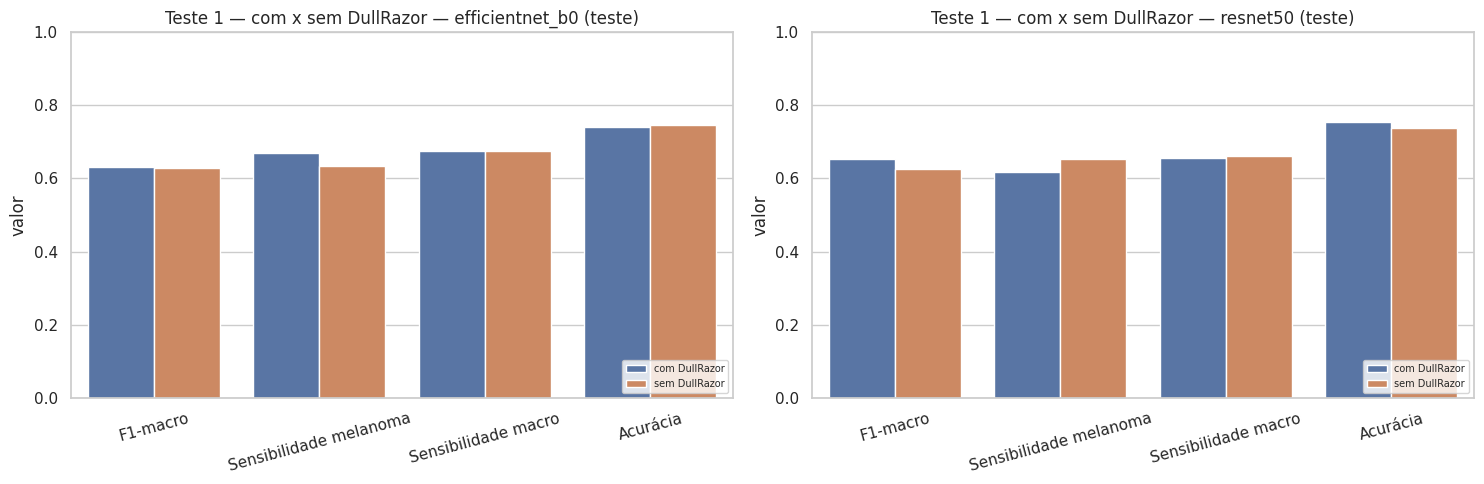

Gráfico salvo em: /content/data/processed/experimentos/comparacao_dullrazor.png


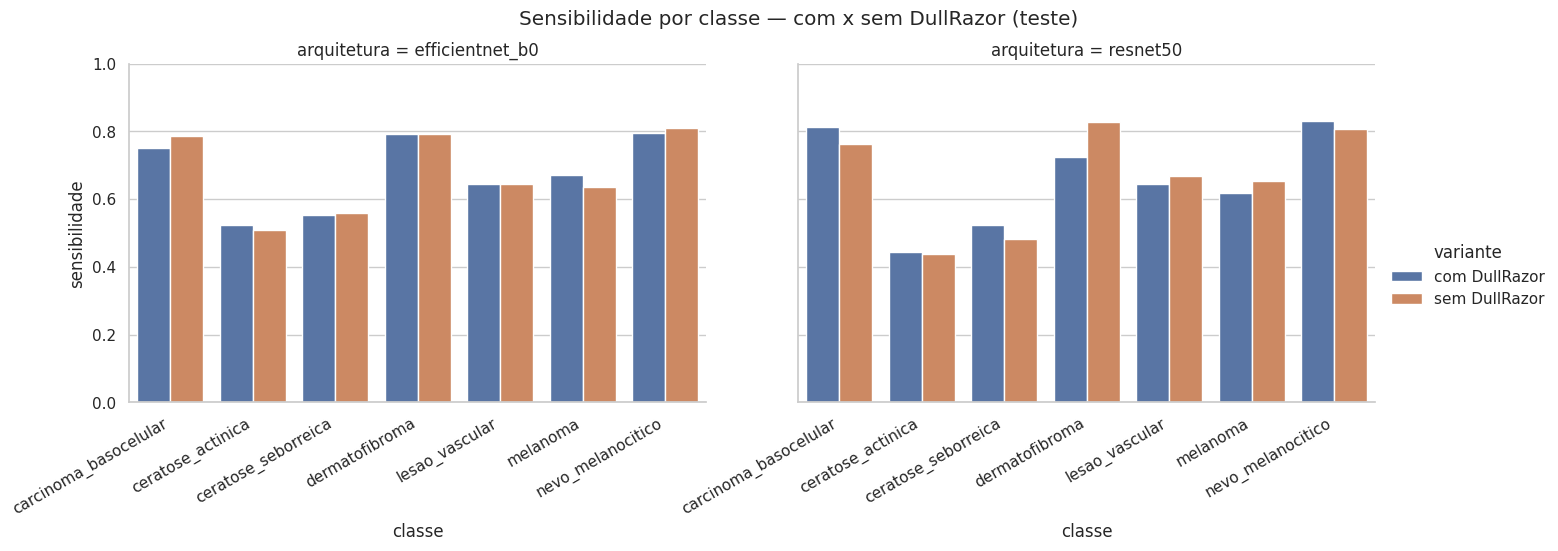

In [ ]:
# ============================================================
# TESTE 1 — COM x SEM DULLRAZOR (imagens tratadas x originais)
# ============================================================
if EXECUTAR["dullrazor"]:
    if not os.path.exists(caminho_csv_split("train", "sem_dullrazor")):
        raise FileNotFoundError("Versão 'sem DullRazor' não encontrada. Rode antes a célula "
                                "'VERSÃO SEM DULLRAZOR' (seção de pré-processamento).")
    res_dr = executar_fator("dullrazor", ARQS_TESTE_DULLRAZOR)
    df_dr = resumir_fator("dullrazor", res_dr, "Teste 1 — com x sem DullRazor")

    # Foco nas classes em que pelos/artefatos mais importam: sensibilidade por classe
    linhas = []
    for rotulo, por_arq in res_dr.items():
        for arq, lista in por_arq.items():
            for classe, rec in lista[0]["teste"]["recall_por_classe"].items():
                linhas.append({"variante": rotulo, "arquitetura": arq, "classe": classe, "sensibilidade": rec})
    df_cls = pd.DataFrame(linhas)
    g = sns.catplot(data=df_cls, x="classe", y="sensibilidade", hue="variante",
                    col="arquitetura", kind="bar", height=4.5, aspect=1.5)
    g.set_xticklabels(rotation=30, ha="right"); g.set(ylim=(0, 1))
    g.figure.suptitle("Sensibilidade por classe — com x sem DullRazor (teste)", y=1.03)
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "dullrazor_sensibilidade_por_classe.png"), dpi=150, bbox_inches="tight")
    plt.show()

#### Teste 2 — alterações de cor (brilho/contraste)

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__original__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=cosine | cor=original | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.6911 acc=0.4479 | Val: loss=1.2759 acc=0.5430 F1m=0.3738 SensMel=0.506 | lr=1.00e-03 | 47.6s
  [Etapa 1] Época 2/4 | Treino: loss=1.3862 acc=0.5248 | Val: loss=1.1069 acc=0.5986 F1m=0.4016 SensMel=0.49

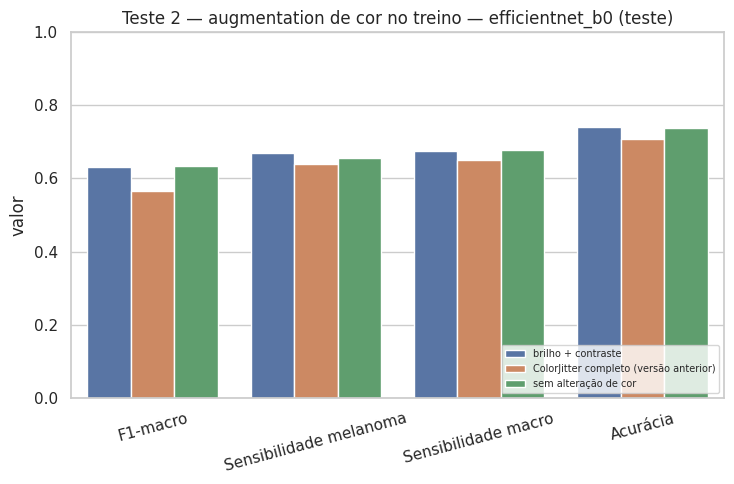

Gráfico salvo em: /content/data/processed/experimentos/comparacao_cor.png


In [ ]:
# ============================================================
# TESTE 2 — ALTERAÇÕES DE COR (brilho/contraste): treino com diferentes augmentations de cor
# ============================================================
if EXECUTAR["cor"]:
    res_cor = executar_fator("cor", [ARQ_ABLACAO])
    df_cor = resumir_fator("cor", res_cor, "Teste 2 — augmentation de cor no treino")

Efeito de cor: 100%|██████████| 150/150 [00:05<00:00, 29.63it/s]


Deslocamento médio de cor causado por cada perturbação (ΔE*ab; ≈2-3 já é perceptível a olho nu):
                    delta_E  var_contraste_L_pct  var_variegacao_ab_pct
perturbacao                                                            
brilho -20%           12.03           -16.930000             -16.709999
brilho +20%           10.95            13.620000              21.559999
contraste -20%         4.83           -18.940001             -21.590000
contraste +20%         4.41            15.760000              22.920000
saturação ±20% (+)     3.56            -1.410000              20.420000
matiz +0,10 (36°)     15.66           -10.690000              10.840000
matiz +0,25 (90°)     31.84           -10.880000              39.669998
matiz +0,50 (180°)    32.43            -5.210000             -20.160000


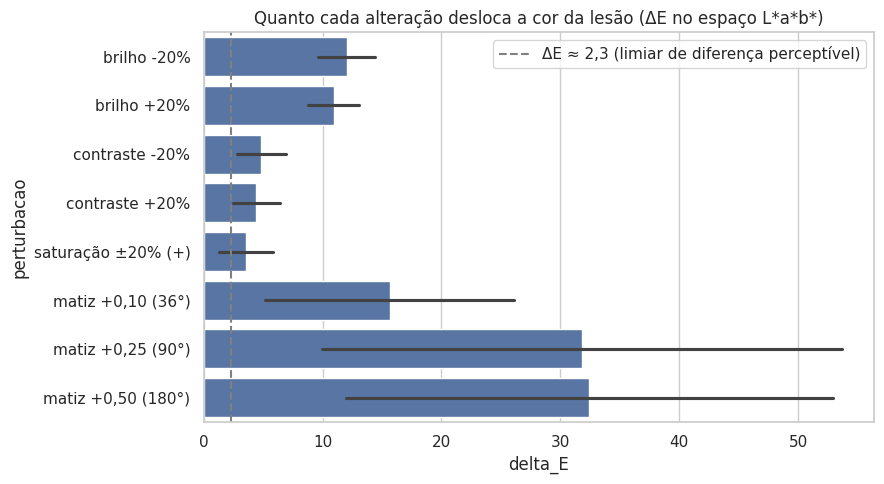

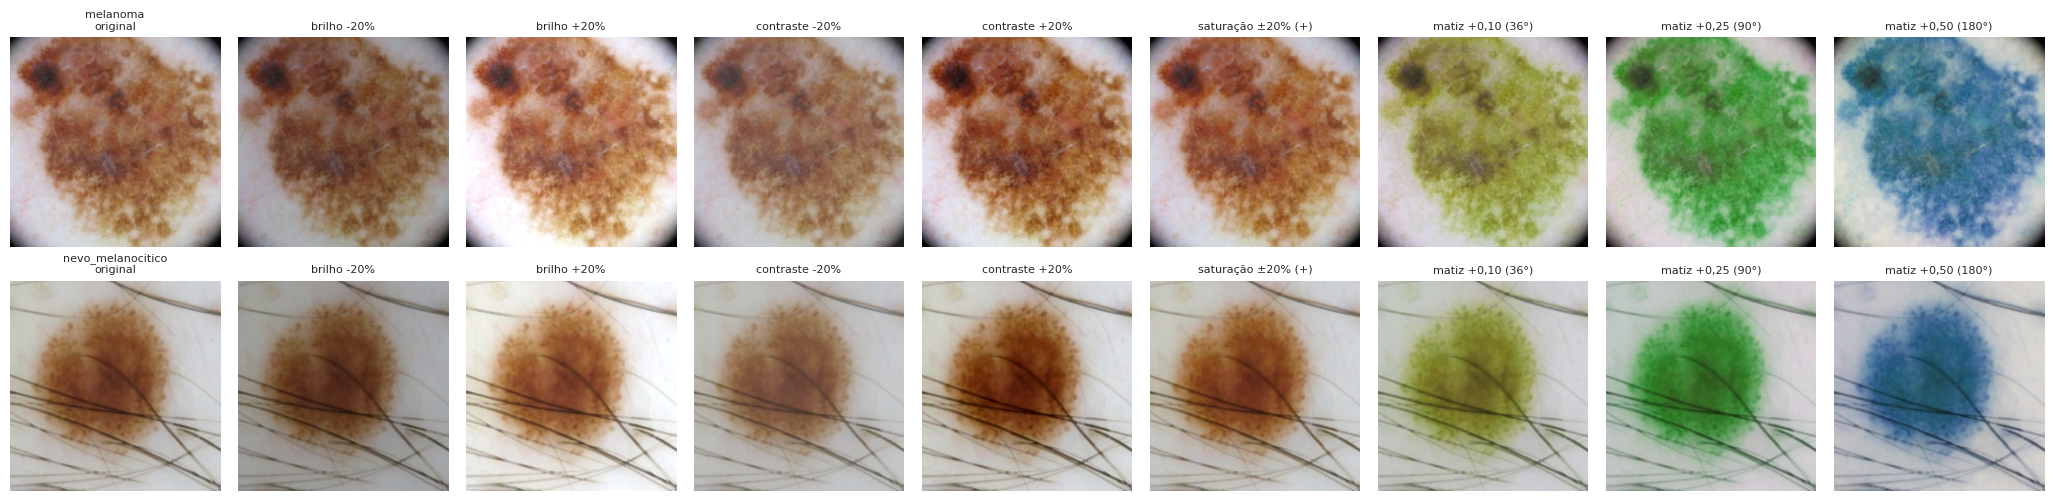

In [ ]:
# ============================================================
# TESTE 2 (cont.) — brilho/contraste/matiz alteram os sinais de COR da lesão? (nível de imagem)
# Mede, em imagens de teste, quanto cada perturbação desloca a cor no espaço CIE L*a*b*.
# ============================================================
PERTURBACOES_IMG = {
    "brilho -20%":        {"brilho": -0.2},
    "brilho +20%":        {"brilho": +0.2},
    "contraste -20%":     {"contraste": -0.2},
    "contraste +20%":     {"contraste": +0.2},
    "saturação ±20% (+)": {"saturacao": +0.2},
    "matiz +0,10 (36°)":  {"matiz": 0.10},
    "matiz +0,25 (90°)":  {"matiz": 0.25},
    "matiz +0,50 (180°)": {"matiz": 0.50},   # equivalente ao pior caso do ColorJitter padrão (versão anterior)
}

def _lab(img_rgb):
    return cv2.cvtColor(img_rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

def analisar_efeito_cor_nas_imagens(n=150, dados=None):
    dados = dados or DADOS_ATIVOS
    df = _ler_split("test", dados)
    df = df.sample(n=min(n, len(df)), random_state=SEED)
    linhas = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="Efeito de cor"):
        img = cv2.cvtColor(cv2.imread(r["caminho_processado"]), cv2.COLOR_BGR2RGB)
        lab0 = _lab(img)
        base_std_L = lab0[..., 0].std()
        base_var_ab = lab0[..., 1].std() + lab0[..., 2].std()   # variegação de cor (proxy do "C" do ABCDE)
        for nome, kw in PERTURBACOES_IMG.items():
            lab1 = _lab(aplicar_perturbacao_cor(img, **kw))
            delta_e = np.sqrt(((lab1 - lab0) ** 2).sum(axis=2)).mean()   # ΔE*ab (CIE76) médio por pixel
            linhas.append({
                "perturbacao": nome, "classe": r["classe"], "delta_E": delta_e,
                "var_contraste_L_pct": 100 * (lab1[..., 0].std() - base_std_L) / (base_std_L + 1e-9),
                "var_variegacao_ab_pct": 100 * ((lab1[..., 1].std() + lab1[..., 2].std()) - base_var_ab) / (base_var_ab + 1e-9),
            })
    df_res = pd.DataFrame(linhas)
    resumo = df_res.groupby("perturbacao", sort=False)[["delta_E", "var_contraste_L_pct", "var_variegacao_ab_pct"]].mean().round(2)
    print("Deslocamento médio de cor causado por cada perturbação (ΔE*ab; ≈2-3 já é perceptível a olho nu):")
    print(resumo.to_string())
    resumo.to_csv(os.path.join(EXPERIMENTOS_DIR, "efeito_cor_nas_imagens.csv"))

    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_res, y="perturbacao", x="delta_E", order=list(PERTURBACOES_IMG), errorbar="sd")
    plt.axvline(2.3, color="gray", ls="--", label="ΔE ≈ 2,3 (limiar de diferença perceptível)")
    plt.title("Quanto cada alteração desloca a cor da lesão (ΔE no espaço L*a*b*)")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "efeito_cor_delta_e.png"), dpi=150)
    plt.show()

    # Exemplo visual: um melanoma e um nevo sob as perturbações
    exemplos = []
    for classe in ["melanoma", "nevo_melanocitico"]:
        sel = df[df["classe"] == classe]
        if len(sel):
            exemplos.append(sel.iloc[0])
    if exemplos:
        nomes = list(PERTURBACOES_IMG)
        fig, eixos = plt.subplots(len(exemplos), len(nomes) + 1, figsize=(2.3 * (len(nomes) + 1), 2.6 * len(exemplos)))
        eixos = np.atleast_2d(eixos)
        for i, r in enumerate(exemplos):
            img = cv2.cvtColor(cv2.imread(r["caminho_processado"]), cv2.COLOR_BGR2RGB)
            eixos[i, 0].imshow(img); eixos[i, 0].set_title(f"{r['classe']}\noriginal", fontsize=8)
            for j, nome in enumerate(nomes, start=1):
                eixos[i, j].imshow(aplicar_perturbacao_cor(img, **PERTURBACOES_IMG[nome]))
                eixos[i, j].set_title(nome, fontsize=8)
            for ax in eixos[i]:
                ax.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(EXPERIMENTOS_DIR, "exemplos_perturbacoes_cor.png"), dpi=150)
        plt.show()
    return resumo

if __name__ == "__main__":
    analisar_efeito_cor_nas_imagens()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


>>> Robustez: brilho + contraste

>>> Robustez: ColorJitter completo (versão anterior)

>>> Robustez: sem alteração de cor

                       variante_treino       tipo  nivel  f1_macro  sens_melanoma  acuracia  pct_predicoes_alteradas
                    brilho + contraste referência    0.0    0.6302         0.6705    0.7408                   0.0000
                    brilho + contraste     brilho   -0.4    0.6147         0.6590    0.7366                  13.1533
                    brilho + contraste     brilho   -0.2    0.6359         0.6639    0.7416                   5.9014
                    brilho + contraste     brilho    0.2    0.6170         0.6573    0.7428                   7.5455
                    brilho + contraste     brilho    0.4    0.5770         0.6359    0.7099                  15.7957
                    brilho + contraste  contraste   -0.4    0.5726         0.4992    0.7137                  16.0012
                    brilho + contraste  contraste   -0.2

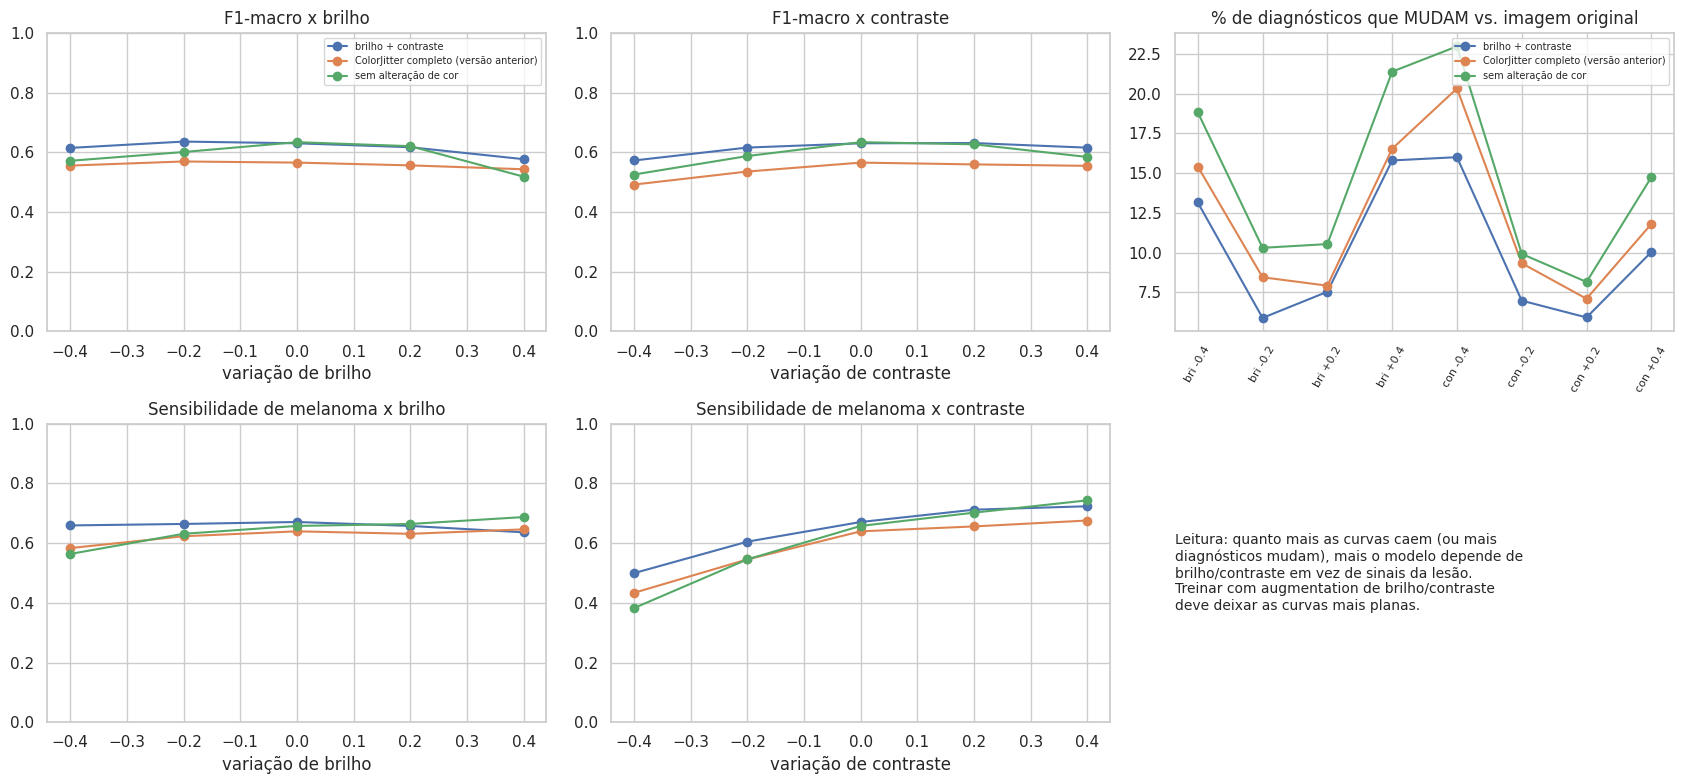

In [ ]:
# ============================================================
# TESTE 2 (cont.) — ROBUSTEZ DOS MODELOS A BRILHO/CONTRASTE NO TESTE
# Aplica perturbações determinísticas ao conjunto de TESTE e mede quanto as predições mudam.
# Um modelo que muda de diagnóstico só por brilho/contraste está usando sinal não clínico.
# ============================================================
NIVEIS_PERTURBACAO = [-0.4, -0.2, 0.2, 0.4]

def carregar_modelo_experimento(arquitetura, num_classes, caminho):
    if arquitetura == "resnet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(arquitetura)
    m.load_state_dict(torch.load(caminho, map_location=DEVICE))
    return m.to(DEVICE).eval()


def predizer_teste(modelo, perturbacao, dados):
    loader, mapa = criar_loader_teste(dados=dados, perturbacao=perturbacao)
    preds, rotulos = [], []
    with torch.no_grad():
        for imagens, rot in loader:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens.to(DEVICE))
            preds.append(saidas.argmax(dim=1).cpu())
            rotulos.append(rot)
    return torch.cat(preds).numpy(), torch.cat(rotulos).numpy(), mapa


def testar_robustez_brilho_contraste():
    linhas = []
    for rotulo, mudancas in FATORES["cor"].items():
        cfg = cfg_ablacao(ARQ_ABLACAO, seed=SEEDS[0], **mudancas)
        caminho = os.path.join(EXPERIMENTOS_DIR, nome_experimento(cfg), "modelo.pt")
        if not os.path.exists(caminho):
            print(f"[AVISO] Checkpoint não encontrado para '{rotulo}' — rode o Teste 2 antes. Pulando.")
            continue
        print(f"\n>>> Robustez: {rotulo}")
        dados = cfg["dados"]
        loader0, mapa = criar_loader_teste(dados=dados)
        modelo = carregar_modelo_experimento(ARQ_ABLACAO, len(mapa), caminho)
        idx_mel = mapa["melanoma"]

        preds_ref, rotulos, _ = predizer_teste(modelo, None, dados)
        cenarios = [("referência", 0.0, 0.0, preds_ref)]
        for tipo in ["brilho", "contraste"]:
            for nivel in NIVEIS_PERTURBACAO:
                p, _, _ = predizer_teste(modelo, {tipo: nivel}, dados)
                cenarios.append((tipo, nivel, None, p))

        for tipo, nivel, _, p in cenarios:
            linhas.append({
                "variante_treino": rotulo,
                "tipo": tipo, "nivel": 0.0 if tipo == "referência" else nivel,
                "f1_macro": f1_score(rotulos, p, labels=list(range(len(mapa))), average="macro", zero_division=0),
                "sens_melanoma": float(((p == idx_mel) & (rotulos == idx_mel)).sum() / max(1, (rotulos == idx_mel).sum())),
                "acuracia": float((p == rotulos).mean()),
                "pct_predicoes_alteradas": float((p != preds_ref).mean() * 100),
            })
        del modelo
        gc.collect(); torch.cuda.empty_cache()

    df = pd.DataFrame(linhas)
    if df.empty:
        return df
    df.to_csv(os.path.join(EXPERIMENTOS_DIR, "robustez_brilho_contraste.csv"), index=False)
    print("\n" + df.round(4).to_string(index=False))

    ref = df[df["tipo"] == "referência"]
    fig, eixos = plt.subplots(2, 3, figsize=(17, 8))
    for j, (tipo, titulo) in enumerate([("brilho", "Brilho"), ("contraste", "Contraste")]):
        for i, (metrica, nome_m) in enumerate([("f1_macro", "F1-macro"), ("sens_melanoma", "Sensibilidade de melanoma")]):
            ax = eixos[i, j]
            for variante, g in df.groupby("variante_treino", sort=False):
                pts = pd.concat([g[g["tipo"] == tipo][["nivel", metrica]],
                                 ref[ref["variante_treino"] == variante][["nivel", metrica]]]).sort_values("nivel")
                ax.plot(pts["nivel"], pts[metrica], marker="o", label=variante)
            ax.set_title(f"{nome_m} x {titulo.lower()}"); ax.set_xlabel(f"variação de {titulo.lower()}")
            ax.set_ylim(0, 1)
    ax = eixos[0, 2]
    for variante, g in df[df["tipo"] != "referência"].groupby("variante_treino", sort=False):
        ax.plot(range(len(g)), g["pct_predicoes_alteradas"].values, marker="o", label=variante)
    rotulos_x = [f"{t[:3]} {n:+.1f}" for t in ["brilho", "contraste"] for n in NIVEIS_PERTURBACAO]
    ax.set_xticks(range(len(rotulos_x))); ax.set_xticklabels(rotulos_x, rotation=60, fontsize=8)
    ax.set_title("% de diagnósticos que MUDAM vs. imagem original"); ax.legend(fontsize=7)
    eixos[1, 2].axis("off")
    eixos[1, 2].text(0, 0.5, "Leitura: quanto mais as curvas caem (ou mais\ndiagnósticos mudam), mais o modelo depende de\nbrilho/contraste em vez de sinais da lesão.\n"
                      "Treinar com augmentation de brilho/contraste\ndeve deixar as curvas mais planas.", fontsize=10, va="center")
    eixos[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "robustez_brilho_contraste.png"), dpi=150)
    plt.show()
    return df

if __name__ == "__main__" and EXECUTAR["robustez_cor"]:
    df_robustez = testar_robustez_brilho_contraste()

#### Teste 3 — Focal Loss × CrossEntropy ponderada

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__focal__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=focal | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.0946 acc=0.4313 | Val: loss=0.7970 acc=0.5387 F1m=0.3784 SensMel=0.473 | lr=1.00e-03 | 44.8s
  [Etapa 1] Época 2/4 | Treino: loss=0.7692 acc=0.5186 | Val: loss=0.7207 acc=

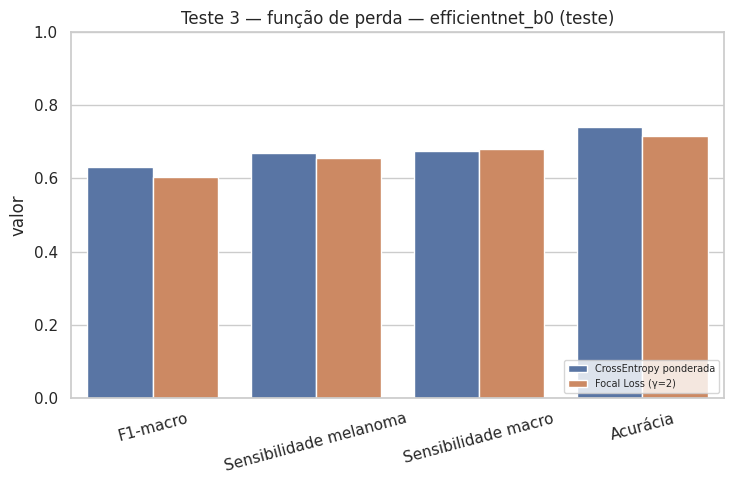

Gráfico salvo em: /content/data/processed/experimentos/comparacao_perda.png

Sensibilidade (recall) e F1 por classe — teste:
                               sensibilidade                                      f1                 
variante              CrossEntropy ponderada Focal Loss (γ=2) CrossEntropy ponderada Focal Loss (γ=2)
classe                                                                                               
carcinoma_basocelular                  0.752            0.743                  0.732            0.719
ceratose_actinica                      0.524            0.524                  0.423            0.401
ceratose_seborreica                    0.553            0.619                  0.506            0.527
dermatofibroma                         0.793            0.793                  0.667            0.590
lesao_vascular                         0.644            0.667                  0.617            0.571
melanoma                               0.671            0.6

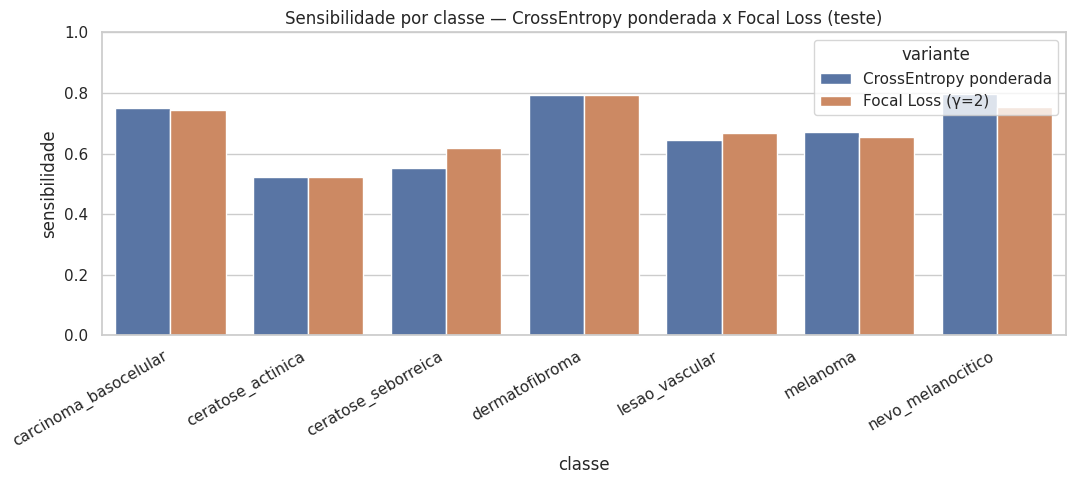

In [ ]:
# ============================================================
# TESTE 3 — FOCAL LOSS x CROSS-ENTROPY PONDERADA
# ============================================================
if EXECUTAR["focal"]:
    res_focal = executar_fator("perda", [ARQ_ABLACAO])
    df_focal = resumir_fator("perda", res_focal, "Teste 3 — função de perda")

    # O que a Focal Loss deveria fazer: melhorar as classes RARAS/DIFÍCEIS sem derrubar as demais.
    linhas = []
    for rotulo, por_arq in res_focal.items():
        r = por_arq[ARQ_ABLACAO][0]
        for classe, rec in r["teste"]["recall_por_classe"].items():
            linhas.append({"variante": rotulo, "classe": classe,
                           "sensibilidade": rec, "f1": r["teste"]["f1_por_classe"][classe]})
    df_cls = pd.DataFrame(linhas)
    print("\nSensibilidade (recall) e F1 por classe — teste:")
    print(df_cls.pivot(index="classe", columns="variante", values=["sensibilidade", "f1"]).round(3).to_string())

    plt.figure(figsize=(11, 5))
    sns.barplot(data=df_cls, x="classe", y="sensibilidade", hue="variante")
    plt.title("Sensibilidade por classe — CrossEntropy ponderada x Focal Loss (teste)")
    plt.xticks(rotation=30, ha="right"); plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "focal_sensibilidade_por_classe.png"), dpi=150)
    plt.show()

#### Teste 4 — escalonador de taxa de aprendizado

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__ce__nenhum__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=nenhum | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.4300 acc=0.5402 | Val: loss=1.1689 acc=0.5757 F1m=0.4032 SensMel=0.485 | lr=1.00e-03 | 43.6s
  [Etapa 1] Época 2/4 | Treino: loss=1.2140 acc=0.5611 | Val: loss=1.0983 acc=0.5933

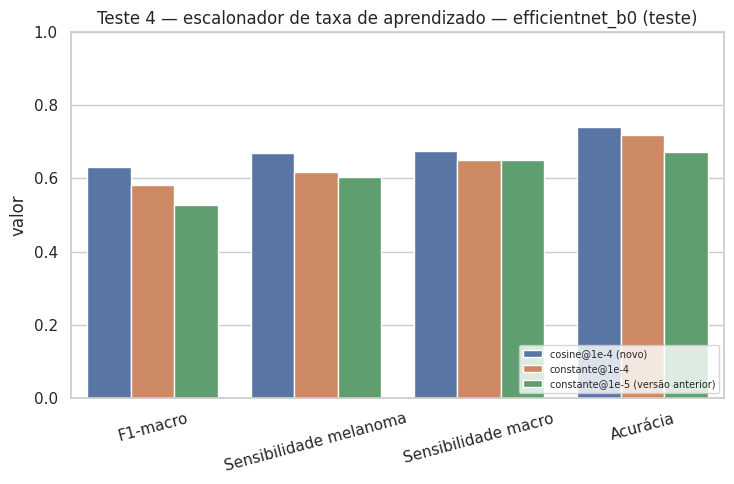

Gráfico salvo em: /content/data/processed/experimentos/comparacao_escalonador.png


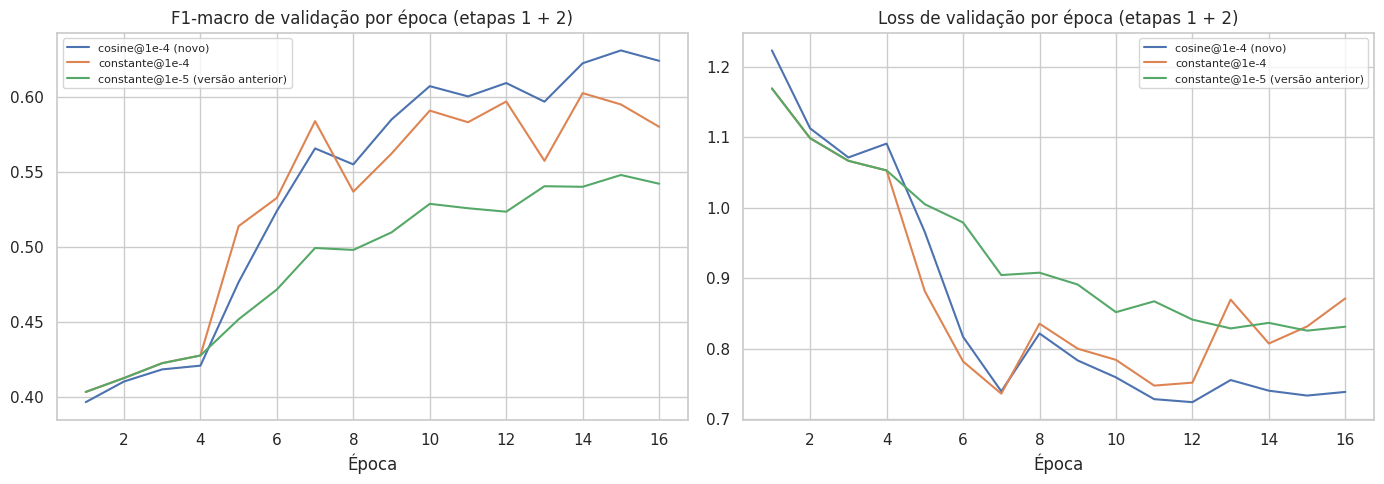

In [ ]:
# ============================================================
# TESTE 4 — ESCALONADOR DE TAXA DE APRENDIZADO
# ============================================================
if EXECUTAR["escalonador"]:
    res_esc = executar_fator("escalonador", [ARQ_ABLACAO])
    df_esc = resumir_fator("escalonador", res_esc, "Teste 4 — escalonador de taxa de aprendizado")

    # Curvas de convergência (F1-macro de validação por época e taxa de aprendizado)
    fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
    for rotulo, por_arq in res_esc.items():
        h = pd.DataFrame(por_arq[ARQ_ABLACAO][0]["historico"])
        h["epoca_global"] = range(1, len(h) + 1)
        eixos[0].plot(h["epoca_global"], h["f1_macro_val"], label=rotulo)
        eixos[1].plot(h["epoca_global"], h["perda_val"], label=rotulo)
    eixos[0].set_title("F1-macro de validação por época (etapas 1 + 2)")
    eixos[1].set_title("Loss de validação por época (etapas 1 + 2)")
    for ax in eixos:
        ax.set_xlabel("Época"); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "convergencia_escalonador.png"), dpi=150)
    plt.show()

In [ ]:
# ============================================================
# ABLACAO EXPLÍCITA EXIGIDA NO TCC: QUATRO CENÁRIOS COMPARÁVEIS
# ============================================================
# Todos os cenários usam o mesmo split sem vazamento, seed, número de épocas e protocolo.
# As épocas de ablação são menores que as do treinamento final para tornar a comparação
# viável; informe esse limite na metodologia e não misture estas métricas com as finais.
EXECUTAR_ABLACAO_TCC = True

CENARIOS_ABLACAO_TCC = [
    {"id": "ResNet50_DR_nao_Focal_nao", "arquitetura": "resnet50", "dados": "sem_dullrazor", "perda": "ce"},
    {"id": "ResNet50_DR_sim_Focal_nao", "arquitetura": "resnet50", "dados": "com_dullrazor", "perda": "ce"},
    {"id": "ResNet50_DR_sim_Focal_sim", "arquitetura": "resnet50", "dados": "com_dullrazor", "perda": "focal", "focal_alpha": "pesos"},
    {"id": "EfficientNetB0_DR_sim_Focal_sim", "arquitetura": "efficientnet_b0", "dados": "com_dullrazor", "perda": "focal", "focal_alpha": "pesos"},
]

if EXECUTAR_ABLACAO_TCC:
    linhas_ab_tcc = []
    for cenario in CENARIOS_ABLACAO_TCC:
        mudancas = {k: cenario[k] for k in ["dados", "perda"]}
        if cenario.get("focal_alpha"):
            mudancas["focal_alpha"] = cenario["focal_alpha"]
        cfg = cfg_ablacao(cenario["arquitetura"], **mudancas)
        resultado = rodar_experimento(cfg)
        teste = resultado["teste"]
        linhas_ab_tcc.append({
            "cenario": cenario["id"], "modelo": cenario["arquitetura"],
            "dullrazor": "Sim" if cenario["dados"] == "com_dullrazor" else "Não",
            "focal_loss": "Sim" if cenario["perda"] == "focal" else "Não",
            "acuracia_balanceada": teste.get("acuracia_balanceada"),
            "macro_f1": teste.get("f1_macro"),
            "recall_melanoma": teste.get("sens_melanoma"),
            "tempo_treinamento_s": resultado.get("tempo_s"),
            "epocas_executadas": len(resultado.get("historico", [])),
        })
    df_ab_tcc = pd.DataFrame(linhas_ab_tcc)
    caminho_ab_tcc = os.path.join(EXPERIMENTOS_DIR, "ablation_tcc_quatro_cenarios.csv")
    df_ab_tcc.to_csv(caminho_ab_tcc, index=False)
    print("\nTabela de ablação exigida pelo TCC:")
    print(df_ab_tcc.round(4).to_string(index=False))
    print(f"Salvo em: {caminho_ab_tcc}")


[CACHE] resnet50__sem_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
[CACHE] resnet50__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: resnet50__com_dullrazor__brilho_contraste__focal__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: resnet50 | perda=focal | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.1292 acc=0.4200 | Val: loss=0.8677 acc=0.5342 F1m=0.3752 SensMel=0.464 | lr=1.00e-03

In [ ]:
import shutil
from google.colab import files

shutil.make_archive('/content/data', 'zip', '/content/data')
files.download('/content/data.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Seleção da configuração final

In [ ]:
# ============================================================
# SELEÇÃO DA CONFIGURAÇÃO FINAL (pelo F1-macro de VALIDAÇÃO)
# ============================================================
def escolher_vencedor(fator, resultados):
    rotulos = list(FATORES[fator])
    base = rotulos[0]

    def score(rotulo):
        return float(np.mean([_media(lista, lambda r: r["val"]["f1_macro"])
                              for lista in resultados[rotulo].values()]))

    pontuacoes = {r: score(r) for r in rotulos if r in resultados}
    melhor = max(pontuacoes, key=pontuacoes.get)
    if melhor != base and pontuacoes[melhor] - pontuacoes[base] < MARGEM_F1_VAL:
        melhor = base   # diferença dentro do ruído: mantém o padrão
    return melhor, pontuacoes


CFG_FINAL = dict(CFG_PADRAO)
decisoes = []
for fator, resultados in RESULTADOS_FATORES.items():
    vencedor, pontuacoes = escolher_vencedor(fator, resultados)
    CFG_FINAL.update(FATORES[fator][vencedor])
    decisoes.append({"fator": fator, "escolha": vencedor,
                     **{f"F1val[{k}]": round(v, 4) for k, v in pontuacoes.items()}})

if decisoes:
    print("DECISÕES (critério: F1-macro de validação; margem mínima = "
          f"{MARGEM_F1_VAL}):")
    for d in decisoes:
        print(f"  - {d['fator']}: {d['escolha']}")
        for k, v in d.items():
            if k.startswith("F1val"):
                print(f"        {k} = {v}")
else:
    print("Nenhum teste foi executado — a configuração final é a padrão (CFG_PADRAO).")

DADOS_ATIVOS = CFG_FINAL["dados"]   # downstream (avaliação, Grad-CAM, equidade) usa a mesma versão das imagens
print("\nCONFIGURAÇÃO FINAL:")
print(json.dumps({k: CFG_FINAL[k] for k in ["dados", "cor", "perda", "focal_gamma", "focal_alpha",
                                              "scheduler", "lr_e1", "lr_e2", "fator_lr_cabeca"]}, indent=2))
with open(os.path.join(EXPERIMENTOS_DIR, "config_final.json"), "w") as f:
    json.dump({"config_final": CFG_FINAL, "decisoes": decisoes}, f, indent=2, default=_json_seguro)

DECISÕES (critério: F1-macro de validação; margem mínima = 0.005):
  - dullrazor: com DullRazor
        F1val[com DullRazor] = 0.6418
        F1val[sem DullRazor] = 0.6255
  - cor: sem alteração de cor
        F1val[brilho + contraste] = 0.6308
        F1val[ColorJitter completo (versão anterior)] = 0.5933
        F1val[sem alteração de cor] = 0.6367
  - perda: CrossEntropy ponderada
        F1val[CrossEntropy ponderada] = 0.6308
        F1val[Focal Loss (γ=2)] = 0.594
  - escalonador: cosine@1e-4 (novo)
        F1val[cosine@1e-4 (novo)] = 0.6308
        F1val[constante@1e-4] = 0.6023
        F1val[constante@1e-5 (versão anterior)] = 0.5478

CONFIGURAÇÃO FINAL:
{
  "dados": "com_dullrazor",
  "cor": "sem_cor",
  "perda": "ce",
  "focal_gamma": 2.0,
  "focal_alpha": "raiz",
  "scheduler": "cosine",
  "lr_e1": 0.001,
  "lr_e2": 0.0001,
  "fator_lr_cabeca": 10.0
}


### Treinamento final com a configuração escolhida

A célula abaixo treina **ResNet50 e EfficientNet-B0 com as épocas completas** usando `CFG_FINAL` (definida na seleção acima; se os experimentos não foram executados, vale `CFG_PADRAO`). Ela salva `modelo_resnet50.pt` e `modelo_efficientnet_b0.pt` em `/content/data/processed/`, que são lidos pelas seções seguintes (avaliação, Grad-CAM e equidade).

**Nota sobre resultados anteriores:** os valores do split antigo foram removidos da comparação automática, pois não são diretamente comparáveis ao novo protocolo agrupado por `lesion_id` e pHash. Use somente os resultados gerados após executar este notebook corrigido.


Dispositivo: cuda

Configuração final: {'dados': 'com_dullrazor', 'cor': 'sem_cor', 'perda': 'ce', 'focal_gamma': 2.0, 'focal_alpha': 'raiz', 'scheduler': 'cosine', 'epocas_e1': 6, 'epocas_e2': 24, 'lr_e1': 0.001, 'lr_e2': 0.0001, 'fator_lr_cabeca': 10.0, 'seed': 42}

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: sem_cor
Classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}

Calculando pesos de classe...

ARQUITETURA: resnet50 | perda=ce | escalonador=cosine | cor=sem_cor | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/6 | Treino: loss=1.6563 acc=0.4934 | Val: loss=1.3288 acc=0.5068 F1m=0.3595 SensMel=0.466 | lr=1.00e-03 

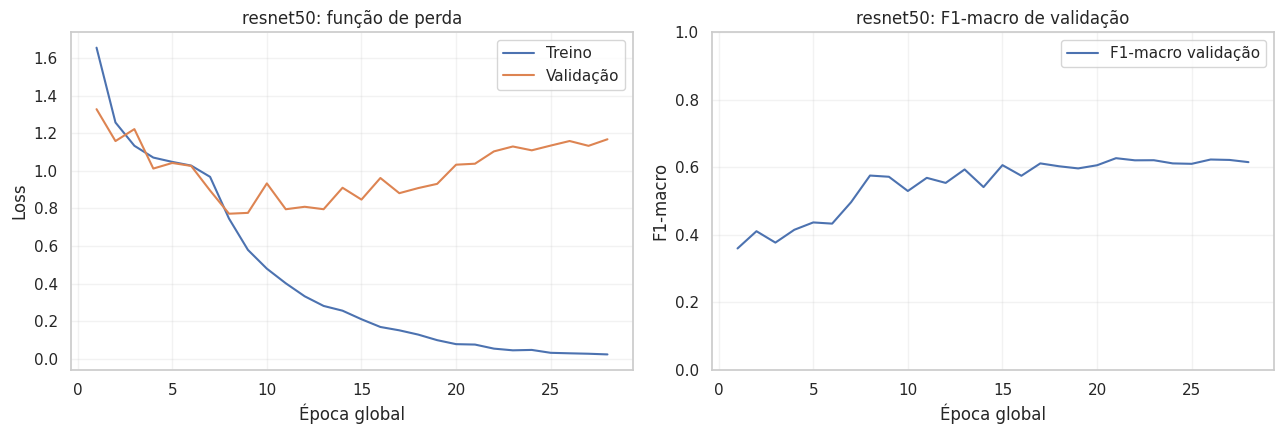

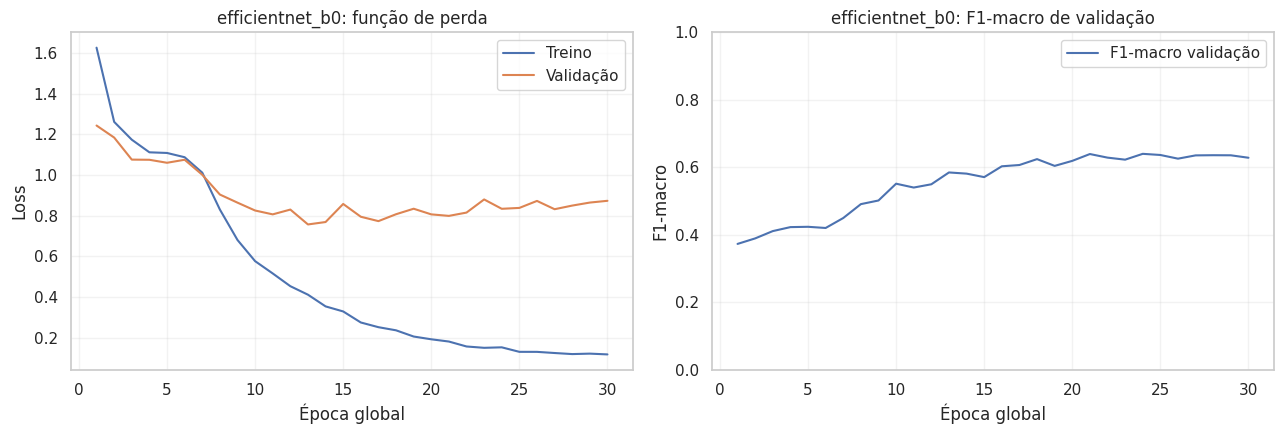


Resultados completos salvos em: /content/data/processed/resultados_comparacao.json


In [ ]:
# ============================================================
# EXECUÇÃO PRINCIPAL — treinamento FINAL (épocas completas) com a configuração escolhida
# nos experimentos (CFG_FINAL). Sem rodar os experimentos, usa a configuração padrão.
# ============================================================
if __name__ == "__main__":
    print(f"Dispositivo: {DEVICE}")
    if DEVICE.type == "cpu":
        print("[AVISO] Sem GPU — esse treinamento completo vai ser MUITO lento em CPU.")

    cfg_final = {**CFG_PADRAO, **CFG_FINAL}
    DADOS_ATIVOS = cfg_final["dados"]
    print(f"\nConfiguração final: {cfg_final}")

    print("\nCarregando DataLoaders...")
    train_loader, val_loader, test_loader, mapa_classes = criar_dataloaders(
        dados=cfg_final["dados"], variante_cor=cfg_final["cor"])
    print(f"Classes: {mapa_classes}")

    print("\nCalculando pesos de classe...")
    pesos_classe = calcular_pesos_classe(train_loader, mapa_classes)

    resultados_comparacao = []
    historicos = {}
    tempos_treinamento = {}
    resumo_epocas = {}

    for arquitetura in ["resnet50", "efficientnet_b0"]:
        fixar_semente(cfg_final["seed"])
        inicio_treino = time.time()
        modelo, historico = treinar_arquitetura(
            arquitetura, train_loader, val_loader, mapa_classes, pesos_classe, cfg=cfg_final
        )
        tempos_treinamento[arquitetura] = time.time() - inicio_treino
        historicos[arquitetura] = historico
        if historico:
            # O checkpoint final é selecionado dentro da etapa 2; não comparar com épocas da etapa 1.
            candidatos_melhor = [h for h in historico if h.get("etapa") == "fine_tuning_completo"] or historico
            melhor_registro = max(candidatos_melhor, key=lambda h: h.get("f1_macro_val", -1))
            resumo_epocas[arquitetura] = {
                "epocas_executadas_total": len(historico),
                "epocas_etapa1": sum(h.get("etapa") == "cabeca_congelada" for h in historico),
                "epocas_etapa2": sum(h.get("etapa") == "fine_tuning_completo" for h in historico),
                "melhor_epoca_global_por_f1_validacao": int(melhor_registro.get("epoca_global", 0)),
                "melhor_epoca_na_etapa2": int(melhor_registro.get("epoca", 0)),
                "melhor_f1_macro_validacao": float(melhor_registro.get("f1_macro_val", float("nan"))),
                "tempo_treinamento_segundos": float(tempos_treinamento[arquitetura]),
                "tempo_treinamento_minutos": float(tempos_treinamento[arquitetura] / 60),
            }

        resultado = avaliar_no_teste(modelo, test_loader, mapa_classes, arquitetura)
        resultado["sens_melanoma"] = resultado["relatorio_completo"]["melanoma"]["recall"]
        resultados_comparacao.append(resultado)

        # Libera memória de GPU antes da próxima arquitetura
        del modelo
        torch.cuda.empty_cache()

    # ============================================================
    # TABELA COMPARATIVA FINAL
    # ============================================================
    print("\n" + "=" * 70)
    print("TABELA COMPARATIVA FINAL — ResNet50 vs. EfficientNet-B0")
    print("=" * 70)
    print(f"{'Métrica':<28}{'ResNet50':>18}{'EfficientNet-B0':>20}")
    print("-" * 70)

    r0, r1 = resultados_comparacao[0], resultados_comparacao[1]
    linhas = [
        ("Acurácia", "acuracia"),
        ("Acurácia balanceada", "acuracia_balanceada"),
        ("Sensibilidade (macro)", "sensibilidade_macro"),
        ("Precisão (macro)", "precisao_macro"),
        ("F1-score (macro)", "f1_macro"),
        ("AUC-ROC (OVR)", "auc_roc_ovr"),
        ("Especificidade média", "especificidade_media"),
        ("Sensibilidade melanoma", "sens_melanoma"),
    ]
    for rotulo, chave in linhas:
        v0 = r0[chave] if r0[chave] is not None else float("nan")
        v1 = r1[chave] if r1[chave] is not None else float("nan")
        print(f"{rotulo:<28}{v0:>18.4f}{v1:>20.4f}")

    # Curvas finais de loss e F1-macro de validação e históricos por época
    pasta_curvas = os.path.join(SAIDA_BASE, "curvas_treinamento")
    os.makedirs(pasta_curvas, exist_ok=True)
    for arquitetura, hist in historicos.items():
        df_hist = pd.DataFrame(hist)
        df_hist.to_csv(os.path.join(pasta_curvas, f"historico_{arquitetura}.csv"), index=False)
        if len(df_hist):
            eixo = df_hist["epoca_global"] if "epoca_global" in df_hist.columns else np.arange(1, len(df_hist) + 1)
            fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
            ax[0].plot(eixo, df_hist["perda_treino"], label="Treino")
            ax[0].plot(eixo, df_hist["perda_val"], label="Validação")
            ax[0].set_title(f"{arquitetura}: função de perda")
            ax[0].set_xlabel("Época global"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=.25)
            ax[1].plot(eixo, df_hist["f1_macro_val"], label="F1-macro validação")
            ax[1].set_title(f"{arquitetura}: F1-macro de validação")
            ax[1].set_xlabel("Época global"); ax[1].set_ylabel("F1-macro"); ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].grid(alpha=.25)
            fig.tight_layout()
            fig.savefig(os.path.join(pasta_curvas, f"curvas_{arquitetura}.png"), dpi=160, bbox_inches="tight")
            plt.show()

    # Salva tudo em JSON para usar depois no capítulo de resultados
    caminho_resultados = os.path.join(SAIDA_BASE, "resultados_comparacao.json")
    with open(caminho_resultados, "w") as f:
        json.dump({
            "config_final": cfg_final,
            "resultados": resultados_comparacao,
            "historicos": historicos,
            "tempos_treinamento": tempos_treinamento,
            "resumo_epocas": resumo_epocas,
            "ambiente": coletar_metadados_ambiente(),
            "mapa_classes": mapa_classes,
        }, f, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
    print(f"\nResultados completos salvos em: {caminho_resultados}")